# 03 · Piloto de viabilidad: 3 preprocesamientos × 6 modelos

**Proyecto:** Predicción del precio de vivienda con aprendizaje automático (UAO · Aprendizaje Automático · 2026-2)
**Tarjeta de Trello:** `T12` · Experimento piloto de viabilidad
**Responsable:** Brandon Eduardo Tobar Sánchez (Model Developer · Evaluation Lead)
**Objetivo:** comprobar que el diseño de T11 es viable y obtener una primera comparación de 18 pipelines (3 preprocesamientos × 6 modelos) con validación cruzada repetida 5 × 3, **usando solo el conjunto de entrenamiento**. Atiende el criterio de *relevancia y viabilidad de la metodología* (15 %) y alimenta la diapositiva 10 de la propuesta.

**Contenido**
1. Preparación del entorno
2. Configuración y semilla
3. Carga del entrenamiento y verificación del aislamiento del test sellado
4. Preprocesamientos P1, P2 y P3
5. Modelos M1–M6 y sus hiperparámetros fijos
6. Validación cruzada repetida 5 × 3
7. Ejecución de los 18 pipelines
8. Tabla de resultados
9. Comparación gráfica
10. Curva de aprendizaje
11. Interpretación de los resultados
12. Limitaciones
13. Conclusiones preliminares
14. Reproducción del experimento

> **Qué es y qué no es este notebook.** Es un **piloto**: estima el error de validación cruzada con hiperparámetros fijos para verificar que el pipeline funciona y para tener una primera lectura. **No** afirma que un modelo sea mejor en el conjunto de prueba: el 20 % sellado de T06 no se toca hasta T25. Las pruebas estadísticas formales (prueba t corregida, Holm) y la validación anidada corresponden a T17–T22.

## 1. Preparación del entorno

La celda siguiente funciona igual en **Google Colab** y en **local**: en Colab clona el repositorio e instala las dependencias (con el secreto `GITHUB_TOKEN` mientras el repositorio sea privado); en local ubica la raíz del repositorio para poder importar `src/`.

In [1]:
# --- Preparación del entorno (Colab o local) ---
import os
import subprocess
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules  # True si el notebook corre en Google Colab

if EN_COLAB:
    from google.colab import userdata

    repo = "github.com/Juanm0331123/ml-precio-vivienda.git"
    try:
        # Token personal guardado como secreto de Colab (necesario mientras el repo sea privado).
        url = f"https://{userdata.get('GITHUB_TOKEN')}@{repo}"
    except Exception:
        url = f"https://{repo}"  # sirve si el repositorio se vuelve público
    if not Path("ml-precio-vivienda").exists():
        subprocess.run(["git", "clone", "-q", url], check=True)
    os.chdir("ml-precio-vivienda")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

# Raíz del repositorio = primera carpeta (actual o superior) que contiene src/.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))  # permite: from src.config import ...
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: D:\ml-precio-vivienda


## 2. Configuración y semilla

Se importan las funciones reutilizables de `src/` (`preprocesamiento.py`, `modelos.py`, `evaluacion.py`) y la semilla global del proyecto (**5007**). Se registran las versiones de las bibliotecas y el equipo, porque los **tiempos** dependen del hardware y los resultados dependen de las versiones.

In [2]:
# --- Librerías y configuración compartida ---
import json
import platform
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import xgboost
from IPython.display import Markdown, display

from src.config import DIR_FIGURAS, DIR_TABLAS, RUTA_DATOS_CRUDOS, SEMILLA, SHA256_DATOS_CRUDOS
from src.evaluacion import (FACTOR_KAGGLE, cargar_entrenamiento, crear_pliegues, curva_aprendizaje,
                            ejecutar_experimento, huella_sha256, resumir)
from src.modelos import HIPERPARAMETROS, MODELOS
from src.preprocesamiento import COLUMNAS_PREDICTORAS, DESCRIPCION

warnings.filterwarnings("ignore", category=FutureWarning)  # avisos de versiones; no afectan a los resultados
np.random.seed(SEMILLA)                       # reproducibilidad (semilla del proyecto: 5007)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
DIR_TABLAS.mkdir(parents=True, exist_ok=True)

ENTORNO = {
    "python": platform.python_version(), "sistema": f"{platform.system()} {platform.release()}",
    "procesador": platform.processor() or "no disponible", "nucleos_logicos": os.cpu_count(),
    "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "semilla": SEMILLA,
}
pd.Series(ENTORNO, name="valor").to_frame()

,valor
python,3.12.10
sistema,Windows 11
procesador,"Intel64 Family 6 Model 154 Stepping 3, Genuine..."
nucleos_logicos,16
numpy,2.5.4
pandas,3.1.1
scipy,1.18.1
scikit-learn,1.9.1
xgboost,3.4.1
semilla,5007


## 3. Carga del entrenamiento y verificación del aislamiento del test sellado

**Qué se hace.** `cargar_entrenamiento()` lee de `data/processed/particion.csv` solo los identificadores y el recuento de cada conjunto, y luego carga de `housing_limpio.csv` **únicamente las filas `entrenamiento`** (salta las líneas de `prueba` al leer). Los valores del test nunca entran a memoria.

**Por qué.** La regla de T06 y de T11 es que el 20 % de prueba queda sellado hasta T25: no se entrena, se evalúa, se ajusta ni se mira. Cargar solo el entrenamiento convierte esa regla en una restricción del código, no solo en un compromiso.

**Qué resultado se espera.** 436 filas de entrenamiento, 0 filas de prueba cargadas, 0 faltantes, y las mismas huellas SHA-256 que los archivos del repositorio (no se modificó nada).

In [3]:
X, y, evidencia = cargar_entrenamiento()

# Verificaciones de aislamiento y de integridad de los datos
assert evidencia["n_entrenamiento_cargado"] == 436 and evidencia["n_prueba_cargado"] == 0
assert evidencia["interseccion_ids_entrenamiento_prueba"] == 0
assert huella_sha256(RUTA_DATOS_CRUDOS) == SHA256_DATOS_CRUDOS, "Housing.csv fue modificado"

print(f"Filas de entrenamiento cargadas: {evidencia['n_entrenamiento_cargado']}")
print(f"Filas de prueba CARGADAS: {evidencia['n_prueba_cargado']} (la partición sellada tiene {evidencia['n_prueba_en_particion']}; solo se usa el recuento)")
print(f"Predictoras: {len(COLUMNAS_PREDICTORAS)} | Faltantes: {int(X.isna().sum().sum())}")
print(f"Escala de price: unidades de Kaggle = dólares canadienses de 1987 × {FACTOR_KAGGLE} (T05); no son precios actuales ni pesos colombianos")
print("SHA-256 particion.csv      :", evidencia["sha256_particion"])
print("SHA-256 housing_limpio.csv :", evidencia["sha256_housing_limpio"])
X.head()

Filas de entrenamiento cargadas: 436
Filas de prueba CARGADAS: 0 (la partición sellada tiene 109; solo se usa el recuento)
Predictoras: 12 | Faltantes: 0
Escala de price: unidades de Kaggle = dólares canadienses de 1987 × 70 (T05); no son precios actuales ni pesos colombianos
SHA-256 particion.csv      : 7c34c251279e7f15b21853d58b37f953f37d56f7aead93a3ef99c50d24013f1f
SHA-256 housing_limpio.csv : e69841956c4328574faa12d5888d056a48ebd55bb5ff0ece69c9c6ba60bb53d5


,area,bedrooms,bathrooms,stories,parking,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
id,,,,,,,,,,,,
0,7420,4,2,3,2,1,0,0,0,1,1,2
2,9960,3,2,2,2,1,0,1,0,0,1,1
3,7500,4,2,2,3,1,0,1,0,1,1,2
4,7420,4,1,2,2,1,1,1,0,1,0,2
5,7500,3,3,1,2,1,0,1,0,1,1,1


**Lectura de T06 que condiciona el diseño.** `housing_limpio.csv` guarda las 6 variables binarias como 0/1 y `furnishingstatus` como entero ordinal (0 = unfurnished, 1 = semi-furnished, 2 = furnished). T11 (sección 3.2) decidió tratar `furnishingstatus` como **nominal**, porque el orden de esa variable —agregada en Kaggle sin documentar— no está justificado. T12 lo resuelve **localmente**: el pipeline expande los tres códigos con *one-hot* (`drop="first"`) sin modificar el archivo de T06 ni la partición.

## 4. Preprocesamientos P1, P2 y P3

Son **acumulativos**: P2 = P1 + transformaciones y P3 = P2 + ingeniería y selección (T11, 3.4). Todo lo que se aprende de los datos va dentro de un `Pipeline` de scikit-learn y se ajusta **solo con las filas de ajuste de cada pliegue**.

| Preprocesamiento | Qué hace | Por qué |
|---|---|---|
| **P1 · Base** | One-hot de `furnishingstatus`; `StandardScaler` en las 5 numéricas solo para Ridge, KNN y SVR; objetivo en escala original | Punto de comparación; OLS y los árboles no necesitan escala |
| **P2 · Transformaciones** | P1 + `log(price)` como objetivo; Yeo-Johnson en `area`; `RobustScaler` en los conteos (Ridge, KNN, SVR) | Precio y `area` tienen cola derecha; el logaritmo vuelve el error relativo (H2) |
| **P3 · Ingeniería y selección** | P2 + 4 variables derivadas (`area_por_dormitorio`, `n_comodidades`, `area_x_prefarea`, `area_x_airconditioning`); winsorización 1–99 % (derivadas con `StandardScaler`); `SelectKBest` por información mutua con k = 10 | Incorporan estructura hedónica; la selección reduce ruido con n pequeño |

**Cómo se comparan en la misma escala.** En P2 y P3 el objetivo se modela como `log(price)` con `TransformedTargetRegressor`, que aplica `exp` a la predicción antes de devolverla. Las métricas de P1, P2 y P3 se calculan, por tanto, **en la escala original de `price`**. Solo SVR estandariza además el objetivo dentro del pliegue (necesidad numérica: `price` es del orden de 10⁶).

*Nota sobre el sesgo de retransformación.* `exp(E[log y])` estima la mediana condicional y no la media, de modo que las predicciones de P2/P3 pueden subestimar en promedio. El piloto lo reporta tal cual; la corrección de *smearing* de Duan queda como análisis de sensibilidad posterior (T11, 3.4).

In [4]:
pd.DataFrame({"preprocesamiento": list(DESCRIPCION), "descripción": list(DESCRIPCION.values())})

,preprocesamiento,descripción
0,P1,"Base: one-hot de furnishingstatus, StandardSca..."
1,P2,"P1 + log(price), Yeo-Johnson en area, RobustSc..."
2,P3,"P2 + variables derivadas, 2 interacciones, win..."


**Decisión de diseño sobre el escalado de las variables derivadas de P3 (diagnóstico).** En una primera ejecución completa, P3 con `RobustScaler` en las derivadas dio un desempeño muy deficiente en los modelos sensibles a la escala (SVR: RMSE ≈ 1,67 millones y R² ≈ 0,18; KNN: RMSE ≈ 1,32 millones; frente a ≈ 1,29 y ≈ 1,22 millones en P2). El diagnóstico de abajo muestra la causa: las derivadas que son interacciones con una binaria tienen más del 75 % de ceros, de modo que su **rango intercuartílico es 0** y `RobustScaler` no las escala (deja valores de miles junto a variables estandarizadas), lo que arruina las distancias y el kernel. Es un defecto de escala, no un resultado de modelado, así que se corrigió **sin tocar hiperparámetros**: las derivadas se winsorizan y se escalan con `StandardScaler`. T11 no fijaba el escalador de las derivadas; esta es una discrepancia local documentada. Los resultados de las secciones siguientes son los de la versión corregida.

In [5]:
from sklearn.preprocessing import RobustScaler, StandardScaler
from src.preprocesamiento import COLUMNAS_DERIVADAS, DerivadorVariables

derivadas = DerivadorVariables().fit_transform(X)[COLUMNAS_DERIVADAS]
diagnostico = pd.DataFrame({
    "% de ceros": (derivadas == 0).mean() * 100,
    "rango intercuartílico": derivadas.quantile(0.75) - derivadas.quantile(0.25),
    "escala que aplica RobustScaler": RobustScaler().fit(derivadas).scale_,
    "escala que aplica StandardScaler": StandardScaler().fit(derivadas).scale_,
})
diagnostico.round(2)

,% de ceros,rango intercuartílico,escala que aplica RobustScaler,escala que aplica StandardScaler
area_por_dormitorio,0.00,951.35,951.35,832.71
n_comodidades,41.51,1.00,1.00,0.90
area_x_prefarea,75.69,0.00,1.00,2780.94
area_x_airconditioning,68.81,4500.00,4500.00,2907.19


## 5. Modelos M1–M6 y sus hiperparámetros fijos

Seis modelos de cuatro familias (T11, 3.5). **El piloto no ajusta hiperparámetros**: se fijaron **antes de ejecutar** el experimento, tomando valores centrales de las rejillas de T11, y no se cambiaron después de ver resultados. Así el error de validación cruzada no se vuelve optimista por haber elegido hiperparámetros con esos mismos datos. La optimización completa es de T19–T22 con validación anidada.

Todos usan `random_state=5007` (cuando lo admiten) y `n_jobs=1`: el piloto es pequeño y un solo hilo da tiempos comparables y resultados reproducibles, sin paralelismo anidado en Windows ni Colab.

In [6]:
tabla_modelos = pd.DataFrame([
    {"id": m, "modelo": nombre, "familia": familia, "hiperparámetros fijos": json.dumps(HIPERPARAMETROS[m], ensure_ascii=False)}
    for m, (nombre, familia, _) in MODELOS.items()
])
tabla_modelos

,id,modelo,familia,hiperparámetros fijos
0,M1,OLS (hedónico),lineal,{}
1,M2,Ridge,lineal,"{""alpha"": 1.0}"
2,M3,KNN,distancia,"{""n_neighbors"": 11, ""weights"": ""uniform"", ""p"":..."
3,M4,SVR (RBF),kernel,"{""kernel"": ""rbf"", ""C"": 10.0, ""epsilon"": 0.1, ""..."
4,M5,Random Forest,árboles,"{""n_estimators"": 500, ""max_depth"": 10, ""min_sa..."
5,M6,XGBoost,árboles,"{""n_estimators"": 300, ""learning_rate"": 0.05, ""..."


## 6. Validación cruzada repetida 5 × 3

**Qué se hace.** Se divide **solo el entrenamiento** (436 filas) en 5 pliegues, y se repite 3 veces con particiones distintas (semilla 5007): 15 evaluaciones por pipeline.

**Por qué.** Con 436 filas, una sola partición tiene mucha varianza. La repetición mide la variabilidad del error, que es lo que necesitan las pruebas estadísticas posteriores.

**Decisión de diseño.** Se usa `RepeatedStratifiedKFold`: es la validación repetida 5 × 3 con los pliegues estratificados por quintiles del precio de entrenamiento, como en T06 y T11 (3.6). Los estratos se calculan solo con el `price` de entrenamiento. La **misma lista de pliegues** se usa para los 18 pipelines, así que cada comparación es pareada. *No* se usa `train_test_split` adicional ni `cross_val_score` sobre los 545 registros.

In [7]:
pliegues = crear_pliegues(y)

# Verificaciones: 15 pliegues, sin solapamiento, y cada fila se valida exactamente una vez por repetición
assert len(pliegues) == 15
assert all(len(set(a) & set(v)) == 0 for a, v in pliegues)
for r in range(3):
    assert sorted(np.concatenate([pliegues[r * 5 + k][1] for k in range(5)])) == list(range(len(y)))

resumen_pliegues = pd.DataFrame({
    "repetición": [k // 5 for k in range(15)], "pliegue": [k % 5 for k in range(15)],
    "filas de ajuste": [len(a) for a, _ in pliegues], "filas de validación": [len(v) for _, v in pliegues],
    "precio medio de validación (unid. Kaggle)": [y.iloc[v].mean() for _, v in pliegues],
})
print("Pliegues:", len(pliegues), "| mismo conjunto de pliegues para los 18 pipelines")
resumen_pliegues.head(6).round(0)

Pliegues: 15 | mismo conjunto de pliegues para los 18 pipelines


,repetición,pliegue,filas de ajuste,filas de validación,precio medio de validación (unid. Kaggle)
0,0,0,348,88,4845193.0
1,0,1,349,87,4759638.0
2,0,2,349,87,4804454.0
3,0,3,349,87,4698160.0
4,0,4,349,87,4761448.0
5,1,0,348,88,4684511.0


## 7. Ejecución de los 18 pipelines

**Qué se hace.** Para cada combinación P×M (18) y cada pliegue (15) se ajusta un pipeline nuevo con las filas de ajuste, se predice en las filas de validación y se calculan RMSE, MAE, MAPE y R² **en la escala original**, junto con el tiempo de ajuste y el de inferencia. Total esperado: 18 × 15 = **270 ajustes**.

**Por qué.** Registrar la métrica por pliegue (sin redondear) permite calcular después medias y desviaciones, y comparar de forma pareada.

**Si algo falla.** El error se registra con la combinación y el pliegue, y no se sustituye por ceros ni se oculta.

In [8]:
PREPROCESAMIENTOS, IDS_MODELOS = ["P1", "P2", "P3"], list(MODELOS)
por_pliegue, fallos, seleccion_p3 = ejecutar_experimento(X, y, pliegues, PREPROCESAMIENTOS, IDS_MODELOS)

n_esperados = len(PREPROCESAMIENTOS) * len(IDS_MODELOS) * len(pliegues)
print(f"Ajustes esperados: {n_esperados} | ajustes válidos: {len(por_pliegue)} | fallos: {len(fallos)}")
assert len(fallos) == 0, fallos
assert len(por_pliegue) == n_esperados
assert np.isfinite(por_pliegue[["rmse", "mae", "mape", "r2", "tiempo_ajuste_s", "tiempo_inferencia_s"]].to_numpy()).all()

por_pliegue.to_csv(DIR_TABLAS / "piloto_resultados_por_pliegue.csv", index=False)
seleccion_p3.to_csv(DIR_TABLAS / "piloto_seleccion_p3.csv", index=False)
(DIR_TABLAS / "piloto_entorno.json").write_text(json.dumps(ENTORNO, indent=2, ensure_ascii=False), encoding="utf-8")
por_pliegue.head(3)

Ajustes esperados: 270 | ajustes válidos: 270 | fallos: 0


,preprocesamiento,modelo,pliegue,repeticion,n_ajuste,n_validacion,tiempo_ajuste_s,tiempo_inferencia_s,rmse,mae,mape,r2,rmse_ajuste
0,P1,M1,0,0,348,88,0.013424,0.006966,1.162695e+06,833317.527718,18.876513,0.633493,1.048439e+06
1,P1,M1,1,0,349,87,0.010740,0.005840,1.062680e+06,788535.290049,17.403881,0.633837,1.076810e+06
2,P1,M1,2,0,349,87,0.008347,0.004243,1.160260e+06,841814.147843,18.564934,0.651108,1.047077e+06


## 8. Tabla de resultados

Se resume por combinación P×M: media y desviación estándar (entre los 15 pliegues, ddof = 1) de cada métrica, número de pliegues válidos y tiempos medios. Se agrega **sin redondear**; el redondeo es solo de presentación. La tabla se ordena por **RMSE medio ascendente** (métrica principal).

**Unidades.** RMSE y MAE están en **unidades de Kaggle** (dólares canadienses de 1987 × 70). Para dar sentido, también se muestran en dólares canadienses de 1987 (÷ 70). **No** son precios actuales ni pesos colombianos. MAPE (%) y R² no dependen de la escala.

In [9]:
resultados = resumir(por_pliegue)
resultados["rmse_cad1987_media"] = resultados["rmse_media"] / FACTOR_KAGGLE
resultados["mae_cad1987_media"] = resultados["mae_media"] / FACTOR_KAGGLE
resultados["brecha_val_ajuste"] = resultados["rmse_media"] / resultados["rmse_ajuste_media"]  # >1: error de validación mayor que en las filas de ajuste

# CSV principal: valores completos, sin redondear
salida = resultados.rename(columns={
    "preprocesamiento": "preprocesamiento", "modelo": "modelo_id", "modelo_nombre": "modelo",
    "n_pliegues_validos": "n_pliegues_validos",
    "tiempo_ajuste_s_media": "tiempo_ajuste_s", "tiempo_inferencia_s_media": "tiempo_inferencia_s"})
salida.to_csv(DIR_TABLAS / "piloto_resultados.csv", index=False)

vista = resultados[["preprocesamiento", "modelo", "modelo_nombre", "familia", "n_pliegues_validos", "rmse_media", "rmse_desv", "rmse_cad1987_media",
                    "mae_media", "mape_media", "r2_media", "tiempo_ajuste_s_media", "tiempo_inferencia_s_media"]].copy()
vista.columns = ["P", "M", "modelo", "familia", "folds", "RMSE", "RMSE desv.", "RMSE (CAD 1987)", "MAE", "MAPE %", "R²", "t. ajuste (s)", "t. inferencia (s)"]
vista.style.format({"RMSE": "{:,.0f}", "RMSE desv.": "{:,.0f}", "RMSE (CAD 1987)": "{:,.0f}", "MAE": "{:,.0f}", "MAPE %": "{:.2f}",
                    "R²": "{:.3f}", "t. ajuste (s)": "{:.4f}", "t. inferencia (s)": "{:.4f}"}).hide(axis="index")

P,M,modelo,familia,folds,RMSE,RMSE desv.,RMSE (CAD 1987),MAE,MAPE %,R²,t. ajuste (s),t. inferencia (s)
P2,M2,Ridge,lineal,15,"1,077,050","130,909","15,386","775,008",16.66,0.663,0.0366,0.0087
P2,M1,OLS (hedónico),lineal,15,"1,077,789","131,977","15,397","776,541",16.69,0.662,0.0352,0.0088
P1,M6,XGBoost,árboles,15,"1,099,481","126,230","15,707","784,872",17.22,0.647,0.0846,0.0083
P1,M2,Ridge,lineal,15,"1,108,595","140,754","15,837","813,211",18.13,0.643,0.0118,0.0070
P1,M1,OLS (hedónico),lineal,15,"1,109,629","141,567","15,852","814,904",18.16,0.642,0.0091,0.0056
P3,M1,OLS (hedónico),lineal,15,"1,117,120","128,611","15,959","803,471",17.56,0.635,0.0879,0.0127
P3,M2,Ridge,lineal,15,"1,117,234","129,053","15,960","803,127",17.55,0.635,0.0918,0.0134
P2,M6,XGBoost,árboles,15,"1,117,359","133,099","15,962","783,105",16.75,0.637,0.0964,0.0114
P1,M5,Random Forest,árboles,15,"1,122,366","135,210","16,034","800,390",17.73,0.634,0.6229,0.0527
P2,M5,Random Forest,árboles,15,"1,138,406","144,956","16,263","793,641",17.00,0.624,0.6600,0.0562


## 9. Comparación gráfica

**Figura 1.** RMSE medio de validación cruzada de las 18 configuraciones; las barras de error son ± 1 desviación estándar entre los 15 pliegues (variabilidad del error, **no** un intervalo de confianza de la media). **Figura 3** (adicional) muestra el compromiso entre error y costo de ajuste.

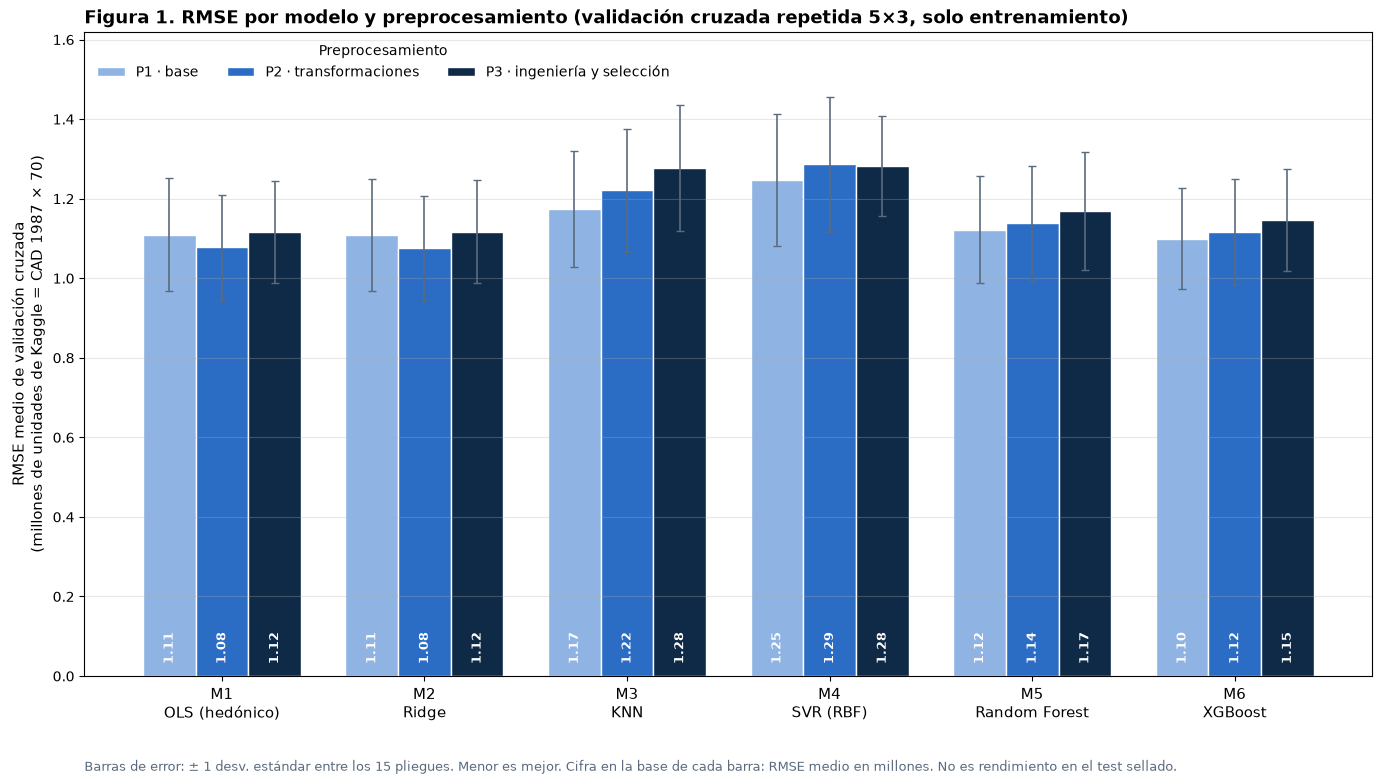

In [10]:
COLOR_P = {"P1": "#8FB3E3", "P2": "#2B6CC4", "P3": "#0F2A47"}
ETIQUETA_M = {m: f"{m}\n{MODELOS[m][0]}" for m in MODELOS}

fig, ax = plt.subplots(figsize=(14, 7.9))
ancho = 0.26
for i, p in enumerate(PREPROCESAMIENTOS):
    sub = resultados[resultados["preprocesamiento"] == p].set_index("modelo").loc[IDS_MODELOS]
    x = np.arange(len(IDS_MODELOS)) + (i - 1) * ancho
    ax.bar(x, sub["rmse_media"] / 1e6, ancho, yerr=sub["rmse_desv"] / 1e6, capsize=3, color=COLOR_P[p],
           edgecolor="white", label={"P1": "P1 · base", "P2": "P2 · transformaciones", "P3": "P3 · ingeniería y selección"}[p],
           error_kw={"elinewidth": 1.2, "ecolor": "#5A6B7E"})
    for xi, v in zip(x, sub["rmse_media"] / 1e6):
        ax.text(xi, 0.03, f"{v:.2f}", rotation=90, ha="center", va="bottom", fontsize=9.5, color="white", fontweight="bold")
mejor = resultados.iloc[0]
ax.set_xticks(np.arange(len(IDS_MODELOS)))
ax.set_xticklabels([ETIQUETA_M[m] for m in IDS_MODELOS], fontsize=11)
ax.set_ylabel("RMSE medio de validación cruzada\n(millones de unidades de Kaggle = CAD 1987 × 70)", fontsize=11)
ax.set_title("Figura 1. RMSE por modelo y preprocesamiento (validación cruzada repetida 5×3, solo entrenamiento)", fontsize=13, fontweight="bold", loc="left")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Preprocesamiento", loc="upper left", ncol=3, frameon=False)
ax.text(0.0, -0.13, "Barras de error: ± 1 desv. estándar entre los 15 pliegues. Menor es mejor. Cifra en la base de cada barra: RMSE medio en millones. No es rendimiento en el test sellado.",
        transform=ax.transAxes, ha="left", va="top", fontsize=9.5, color="#5A6B7E")
ax.set_ylim(0, 1.62)
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "fig_piloto_rmse.png", dpi=200, bbox_inches="tight")
plt.show()

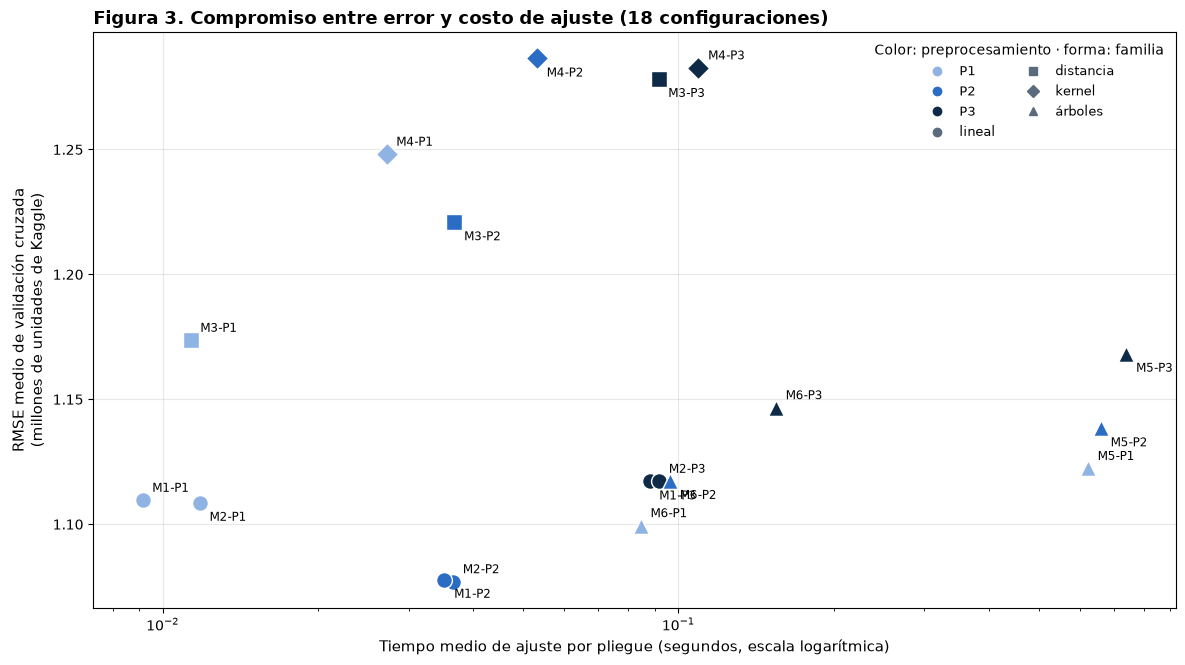

In [11]:
# Figura 3 (adicional): compromiso entre error de validación y costo de ajuste
fig, ax = plt.subplots(figsize=(12, 6.75))
marcador = {"lineal": "o", "distancia": "s", "kernel": "D", "árboles": "^"}
for k, (_, r) in enumerate(resultados.iterrows()):
    ax.scatter(r["tiempo_ajuste_s_media"], r["rmse_media"] / 1e6, s=130, marker=marcador[r["familia"]], color=COLOR_P[r["preprocesamiento"]], edgecolor="white", zorder=3)
    ax.annotate(f"{r['modelo']}-{r['preprocesamiento']}", (r["tiempo_ajuste_s_media"], r["rmse_media"] / 1e6), textcoords="offset points", xytext=(7, 6) if k % 2 == 0 else (7, -13), fontsize=8.5)
ax.set_xscale("log")
ax.set_xlabel("Tiempo medio de ajuste por pliegue (segundos, escala logarítmica)", fontsize=11)
ax.set_ylabel("RMSE medio de validación cruzada\n(millones de unidades de Kaggle)", fontsize=11)
ax.set_title("Figura 3. Compromiso entre error y costo de ajuste (18 configuraciones)", fontsize=13, fontweight="bold", loc="left")
ax.grid(alpha=0.3)
from matplotlib.lines import Line2D
manijas = [Line2D([], [], marker="o", ls="", color=c, label=p) for p, c in COLOR_P.items()] + \
          [Line2D([], [], marker=m, ls="", color="#5A6B7E", label=f) for f, m in marcador.items()]
ax.legend(handles=manijas, title="Color: preprocesamiento · forma: familia", loc="upper right", ncol=2, frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "fig_piloto_rmse_vs_tiempo.png", dpi=200, bbox_inches="tight")
plt.show()

## 10. Curva de aprendizaje

**Qué se hace.** Para una configuración, se mide el RMSE sobre las filas de ajuste y sobre las de validación cuando el ajuste usa una fracción creciente (20 % a 100 %) de las filas de ajuste de cada pliegue. Se usan los **mismos 15 pliegues** y solo entrenamiento.

**Qué configuraciones y por qué.** Se declaran con una regla fija, no por su apariencia: (a) la **mejor configuración observada** en la tabla (menor RMSE medio) y (b) la **línea base hedónica** M1 · P1 (OLS con objetivo en escala original), que es el punto de referencia del proyecto.

**Cómo interpretarla.**
- *Sobreajuste:* error de ajuste muy bajo y error de validación alto, con una **brecha** grande entre ambas curvas.
- *Subajuste:* ambas curvas altas y cercanas entre sí; más datos no ayudan.
- *Brecha de generalización:* distancia entre la curva de validación y la de ajuste con todos los datos.
- *Efecto de más datos:* si la curva de validación **sigue bajando** al final, más datos probablemente mejorarían el modelo; si se aplana, no.

**Costo.** 2 configuraciones × 6 tamaños × 15 pliegues = 180 ajustes adicionales. Se barajan las filas antes de submuestrear (`shuffle=True`): el archivo viene ordenado por precio descendente (T06) y sin barajar las primeras filas serían las más caras.

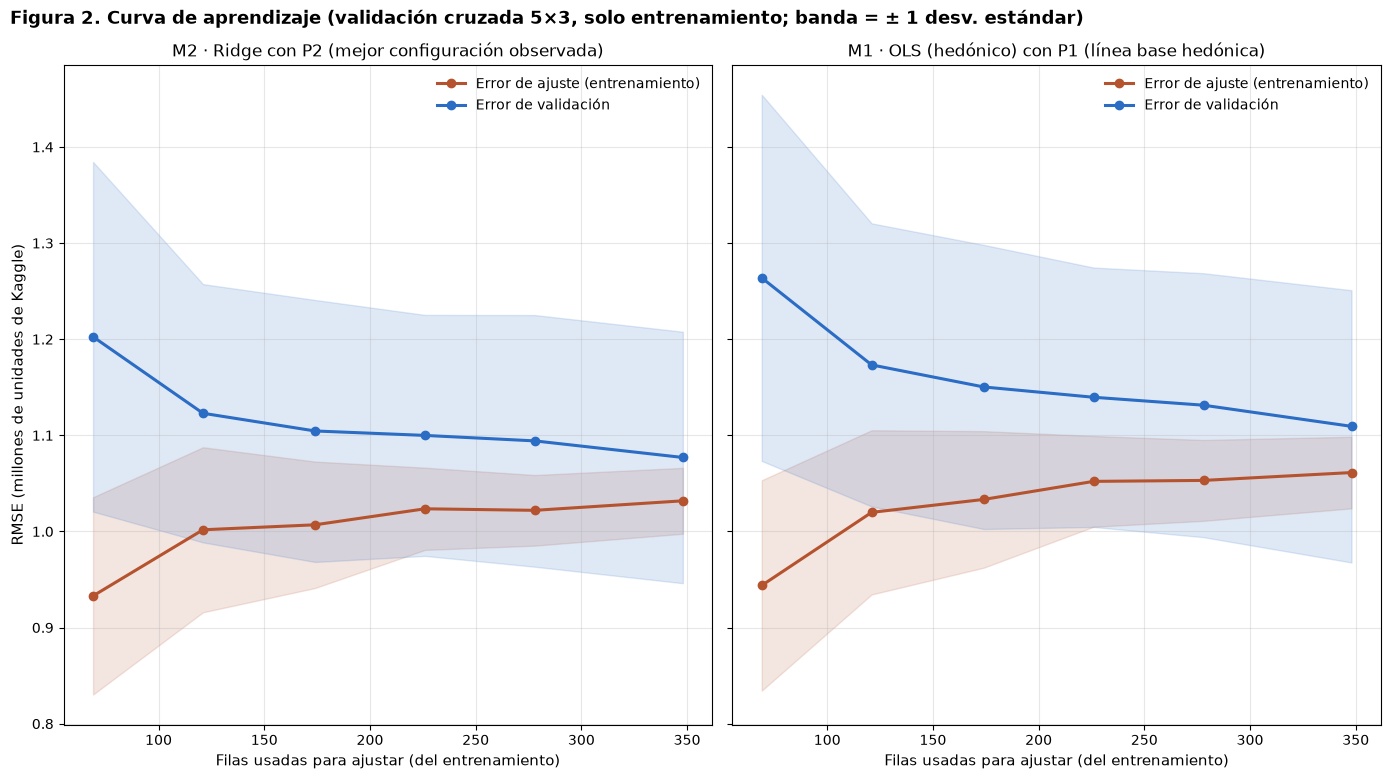

In [12]:
cfg_mejor = (resultados.iloc[0]["preprocesamiento"], resultados.iloc[0]["modelo"])
cfg_base = ("P1", "M1")
configs = [cfg_mejor] if cfg_mejor == cfg_base else [cfg_mejor, cfg_base]
curvas = pd.concat([curva_aprendizaje(X, y, pliegues, p, m) for p, m in configs], ignore_index=True)
curvas.to_csv(DIR_TABLAS / "piloto_curva_aprendizaje.csv", index=False)

fig, ejes = plt.subplots(1, len(configs), figsize=(14, 7.9), sharey=True, squeeze=False)
for ax, (p, m) in zip(ejes[0], configs):
    c = curvas[(curvas["preprocesamiento"] == p) & (curvas["modelo"] == m)]
    g = c.groupby("n_ajuste")[["rmse_ajuste", "rmse_validacion"]].agg(["mean", "std"])
    for col, color, etiqueta in (("rmse_ajuste", "#B5532F", "Error de ajuste (entrenamiento)"), ("rmse_validacion", "#2B6CC4", "Error de validación")):
        ax.plot(g.index, g[(col, "mean")] / 1e6, marker="o", color=color, label=etiqueta, lw=2.2)
        ax.fill_between(g.index, (g[(col, "mean")] - g[(col, "std")]) / 1e6, (g[(col, "mean")] + g[(col, "std")]) / 1e6, color=color, alpha=0.15)
    titulo = "mejor configuración observada" if (p, m) == cfg_mejor else "línea base hedónica"
    ax.set_title(f"{m} · {MODELOS[m][0]} con {p} ({titulo})", fontsize=12)
    ax.set_xlabel("Filas usadas para ajustar (del entrenamiento)", fontsize=11)
    ax.grid(alpha=0.3)
    ax.legend(frameon=False, loc="upper right")
ejes[0][0].set_ylabel("RMSE (millones de unidades de Kaggle)", fontsize=11)
fig.suptitle("Figura 2. Curva de aprendizaje (validación cruzada 5×3, solo entrenamiento; banda = ± 1 desv. estándar)", fontsize=13, fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "fig_curva_aprendizaje.png", dpi=200, bbox_inches="tight")
plt.show()

## 11. Interpretación de los resultados

Las cifras de esta sección se **calculan desde la tabla** (no se escriben a mano), de modo que siempre coinciden con el experimento. La lectura es descriptiva: una media menor **no** equivale a significancia estadística (eso se evalúa con la prueba t corregida en T17–T22) ni garantiza el mismo orden en el test sellado.

In [13]:
r = resultados.set_index(["preprocesamiento", "modelo"])
f = lambda v: f"{v:,.0f}"
lineas = []

b = resultados.iloc[0]
lineas.append(f"**Menor RMSE medio observado:** {b['modelo']} · {b['modelo_nombre']} con {b['preprocesamiento']}: RMSE = {f(b['rmse_media'])} "
              f"(± {f(b['rmse_desv'])} entre pliegues) unidades de Kaggle ≈ {f(b['rmse_cad1987_media'])} CAD de 1987; MAE = {f(b['mae_media'])}; MAPE = {b['mape_media']:.2f} %; R² = {b['r2_media']:.3f}.")

lin = resultados[resultados["familia"] == "lineal"].iloc[0]
arb = resultados[resultados["familia"] == "árboles"].iloc[0]
lineas.append(f"**Mejor modelo lineal:** {lin['modelo']} · {lin['modelo_nombre']} con {lin['preprocesamiento']}: RMSE = {f(lin['rmse_media'])} (± {f(lin['rmse_desv'])}). "
              f"**Mejor de árboles:** {arb['modelo']} · {arb['modelo_nombre']} con {arb['preprocesamiento']}: RMSE = {f(arb['rmse_media'])} (± {f(arb['rmse_desv'])}).")
dif = (lin["rmse_media"] - arb["rmse_media"]) / lin["rmse_media"] * 100
lineas.append(f"Entre ambos, el RMSE medio del mejor modelo de árboles es {abs(dif):.1f} % {'menor' if dif > 0 else 'mayor'} que el del mejor lineal; "
              f"la desviación entre pliegues de cada uno es de {f(lin['rmse_desv'])} y {f(arb['rmse_desv'])}, es decir, del mismo orden que la diferencia entre medias de {f(abs(lin['rmse_media'] - arb['rmse_media']))}"
              f"{', por lo que esta diferencia no debe leerse como concluyente sin una prueba estadística' if abs(lin['rmse_media'] - arb['rmse_media']) < 2 * max(lin['rmse_desv'], arb['rmse_desv']) else ''}.")

# Efecto de P1 -> P2 y de P2 -> P3 por modelo (descriptivo)
filas = []
for m in IDS_MODELOS:
    a, b2, c = (r.loc[(p, m), "rmse_media"] for p in PREPROCESAMIENTOS)
    filas.append({"modelo": f"{m} · {MODELOS[m][0]}", "P1": a, "P2": b2, "P3": c, "P2 vs P1 (%)": (b2 - a) / a * 100, "P3 vs P2 (%)": (c - b2) / b2 * 100,
                  "MAPE P1 %": r.loc[("P1", m), "mape_media"], "MAPE P2 %": r.loc[("P2", m), "mape_media"]})
efecto = pd.DataFrame(filas)
mejora_p2 = int((efecto["P2 vs P1 (%)"] < 0).sum()); mejora_p3 = int((efecto["P3 vs P2 (%)"] < 0).sum())
ld = efecto["modelo"].str[:2].isin(["M1", "M2", "M3"])                      # modelos lineales y basados en distancia (criterio de H2)
mape_baja_ld = int((efecto.loc[ld, "MAPE P2 %"] < efecto.loc[ld, "MAPE P1 %"]).sum())
mape_baja_todos = int((efecto["MAPE P2 %"] < efecto["MAPE P1 %"]).sum())
lineas.append(f"**P2 frente a P1:** el RMSE medio baja en {mejora_p2} de 6 modelos; **P3 frente a P2:** baja en {mejora_p3} de 6 (tabla de abajo, descriptivo). **MAPE (criterio de H2):** baja de P1 a P2 en {mape_baja_ld} de los 3 modelos lineales o de distancia (M1, M2, M3) y en {mape_baja_todos} de 6 en total.")
display(Markdown("\n\n".join(f"- {l}" for l in lineas)))
efecto.style.format({"P1": "{:,.0f}", "P2": "{:,.0f}", "P3": "{:,.0f}", "P2 vs P1 (%)": "{:+.1f}", "P3 vs P2 (%)": "{:+.1f}", "MAPE P1 %": "{:.2f}", "MAPE P2 %": "{:.2f}"}).hide(axis="index")

- **Menor RMSE medio observado:** M2 · Ridge con P2: RMSE = 1,077,050 (± 130,909 entre pliegues) unidades de Kaggle ≈ 15,386 CAD de 1987; MAE = 775,008; MAPE = 16.66 %; R² = 0.663.

- **Mejor modelo lineal:** M2 · Ridge con P2: RMSE = 1,077,050 (± 130,909). **Mejor de árboles:** M6 · XGBoost con P1: RMSE = 1,099,481 (± 126,230).

- Entre ambos, el RMSE medio del mejor modelo de árboles es 2.1 % mayor que el del mejor lineal; la desviación entre pliegues de cada uno es de 130,909 y 126,230, es decir, del mismo orden que la diferencia entre medias de 22,431, por lo que esta diferencia no debe leerse como concluyente sin una prueba estadística.

- **P2 frente a P1:** el RMSE medio baja en 2 de 6 modelos; **P3 frente a P2:** baja en 1 de 6 (tabla de abajo, descriptivo). **MAPE (criterio de H2):** baja de P1 a P2 en 3 de los 3 modelos lineales o de distancia (M1, M2, M3) y en 6 de 6 en total.

modelo,P1,P2,P3,P2 vs P1 (%),P3 vs P2 (%),MAPE P1 %,MAPE P2 %
M1 · OLS (hedónico),"1,109,629","1,077,789","1,117,120",-2.9,+3.6,18.16,16.69
M2 · Ridge,"1,108,595","1,077,050","1,117,234",-2.8,+3.7,18.13,16.66
M3 · KNN,"1,173,656","1,220,872","1,278,230",+4.0,+4.7,18.35,17.52
M4 · SVR (RBF),"1,248,158","1,286,418","1,282,701",+3.1,-0.3,19.07,18.86
M5 · Random Forest,"1,122,366","1,138,406","1,168,221",+1.4,+2.6,17.73,17.00
M6 · XGBoost,"1,099,481","1,117,359","1,146,690",+1.6,+2.6,17.22,16.75


In [14]:
# Comparación pareada y descriptiva por pliegue: ¿en cuántos de los 15 pliegues el mejor de árboles tiene menor RMSE que OLS (M1·P1)?
base = por_pliegue[(por_pliegue["preprocesamiento"] == "P1") & (por_pliegue["modelo"] == "M1")].sort_values("pliegue")["rmse"].to_numpy()
mejor_arb = por_pliegue[(por_pliegue["preprocesamiento"] == arb["preprocesamiento"]) & (por_pliegue["modelo"] == arb["modelo"])].sort_values("pliegue")["rmse"].to_numpy()
mejor_cfg = por_pliegue[(por_pliegue["preprocesamiento"] == b["preprocesamiento"]) & (por_pliegue["modelo"] == b["modelo"])].sort_values("pliegue")["rmse"].to_numpy()
display(Markdown(
    f"- **M1·P1 (OLS base) frente al mejor de árboles ({arb['modelo']}·{arb['preprocesamiento']}):** el segundo tiene menor RMSE en {int((mejor_arb < base).sum())} de 15 pliegues; "
    f"diferencia media por pliegue = {np.mean(base - mejor_arb):,.0f} (desv. {np.std(base - mejor_arb, ddof=1):,.0f}).\n"
    f"- **M1·P1 frente a la mejor configuración observada ({b['modelo']}·{b['preprocesamiento']}):** menor RMSE en {int((mejor_cfg < base).sum())} de 15 pliegues; "
    f"diferencia media = {np.mean(base - mejor_cfg):,.0f} (desv. {np.std(base - mejor_cfg, ddof=1):,.0f}).\n"
    f"- Conteo descriptivo, no una prueba de hipótesis."))

- **M1·P1 (OLS base) frente al mejor de árboles (M6·P1):** el segundo tiene menor RMSE en 8 de 15 pliegues; diferencia media por pliegue = 10,148 (desv. 76,227).
- **M1·P1 frente a la mejor configuración observada (M2·P2):** menor RMSE en 13 de 15 pliegues; diferencia media = 32,579 (desv. 27,336).
- Conteo descriptivo, no una prueba de hipótesis.

In [15]:
# Señales de sobreajuste: cociente entre el RMSE de validación y el RMSE sobre las filas de ajuste (1 = sin brecha)
brecha = resultados[["preprocesamiento", "modelo", "modelo_nombre", "rmse_ajuste_media", "rmse_media", "brecha_val_ajuste"]].copy()
brecha.columns = ["P", "M", "modelo", "RMSE ajuste", "RMSE validación", "validación / ajuste"]
display(Markdown("**Brecha entre error de validación y error de ajuste** (cociente alto = más sobreajuste; se ordena de mayor a menor):"))
brecha.sort_values("validación / ajuste", ascending=False).head(8).style.format({"RMSE ajuste": "{:,.0f}", "RMSE validación": "{:,.0f}", "validación / ajuste": "{:.2f}"}).hide(axis="index")

**Brecha entre error de validación y error de ajuste** (cociente alto = más sobreajuste; se ordena de mayor a menor):

P,M,modelo,RMSE ajuste,RMSE validación,validación / ajuste
P2,M4,SVR (RBF),"439,280","1,286,418",2.93
P1,M4,SVR (RBF),"426,454","1,248,158",2.93
P3,M4,SVR (RBF),"632,155","1,282,701",2.03
P1,M6,XGBoost,"618,430","1,099,481",1.78
P3,M6,XGBoost,"665,474","1,146,690",1.72
P2,M6,XGBoost,"659,549","1,117,359",1.69
P3,M5,Random Forest,"810,467","1,168,221",1.44
P1,M5,Random Forest,"794,345","1,122,366",1.41


In [16]:
# Costo computacional (promedio por pliegue; hardware y versiones en la sección 2)
costo = resultados.groupby(["modelo", "modelo_nombre"], as_index=False)[["tiempo_ajuste_s_media", "tiempo_inferencia_s_media"]].mean().sort_values("tiempo_ajuste_s_media")
costo.columns = ["M", "modelo", "ajuste (s)", "inferencia (s, 87-88 filas)"]
costo.style.format({"ajuste (s)": "{:.4f}", "inferencia (s, 87-88 filas)": "{:.5f}"}).hide(axis="index")

M,modelo,ajuste (s),"inferencia (s, 87-88 filas)"
M1,OLS (hedónico),0.0441,0.00904
M3,KNN,0.0466,0.01138
M2,Ridge,0.0467,0.00971
M4,SVR (RBF),0.0633,0.01329
M6,XGBoost,0.1119,0.01116
M5,Random Forest,0.6741,0.05621


## 12. Limitaciones

- **Es un piloto con hiperparámetros fijos.** El error de cada modelo depende de valores elegidos de antemano; un modelo con otros hiperparámetros podría cambiar el orden. El ajuste correcto es trabajo de T19–T22 con validación anidada.
- **Sin pruebas estadísticas.** Las medias y desviaciones describen la variabilidad entre pliegues, pero no hay una prueba de diferencia entre modelos (prueba t corregida y Holm, T17–T22). Los pliegues repetidos **no son independientes**: la desviación no es un error estándar.
- **Muestra pequeña** (436 filas de ajuste; 348–349 por pliegue): alta varianza y riesgo de sobreajuste.
- **No es rendimiento sobre el test.** Las 109 filas selladas no se usaron; el error final es de T25.
- **Datos históricos y escalados.** Windsor (Canadá), 1987; `price` de Kaggle = CAD 1987 × 70. Nada de esto se interpreta como precio actual ni colombiano.
- **Retransformación de `log(price)`.** P2 y P3 devuelven una estimación que tiende a la mediana condicional; el efecto sobre el RMSE no se corrigió en el piloto.
- **Diseño de P3 fijado a priori.** Las variables derivadas, las interacciones y k = 10 se eligieron por justificación hedónica de T11, no por búsqueda; su contribución real se mide por ablación en T17–T18.
- **Tiempos dependientes del equipo.** Se midieron en un solo hilo en el equipo de la sección 2; sirven para comparar modelos entre sí, no como valores absolutos.
- **Asociación, no causalidad.** Nada de lo anterior sustenta una interpretación causal.

## 13. Conclusiones preliminares

Las respuestas siguientes se redactan a partir de la tabla y las figuras de este notebook; las cifras se generan en la celda y no se copian a mano.

In [17]:
rmse_p = resultados.groupby("preprocesamiento")["rmse_media"].mean()
sobre = brecha.sort_values("validación / ajuste", ascending=False).iloc[0]
c_lento = costo.iloc[-1]; c_rapido = costo.iloc[0]
texto = [
    f"1. **¿Qué combinación obtuvo menor RMSE?** {b['modelo']} · {b['modelo_nombre']} con {b['preprocesamiento']} (RMSE medio {f(b['rmse_media'])}, desv. {f(b['rmse_desv'])}; MAPE {b['mape_media']:.2f} %; R² {b['r2_media']:.3f}).",
    f"2. **¿Los modelos de árboles mejoraron frente al lineal?** El mejor de árboles ({arb['modelo']}·{arb['preprocesamiento']}, {f(arb['rmse_media'])}) frente al mejor lineal ({lin['modelo']}·{lin['preprocesamiento']}, {f(lin['rmse_media'])}): el RMSE del mejor de árboles es {abs(dif):.1f} % {'menor' if dif > 0 else 'mayor'} que el del mejor lineal. "
    f"Con la variabilidad entre pliegues observada, esto es una **señal para H1, no una prueba**.",
    f"3. **¿P2 redujo el error respecto de P1?** En {mejora_p2} de 6 modelos el RMSE medio bajó; el promedio de RMSE entre los 6 modelos pasa de {f(rmse_p['P1'])} (P1) a {f(rmse_p['P2'])} (P2). El MAPE, que es el criterio de **H2**, baja en {mape_baja_ld} de los 3 modelos lineales o de distancia. Es una lectura descriptiva; H2 se contrasta formalmente con los mismos pliegues en T17–T18.",
    f"4. **¿P3 aportó beneficios medibles?** En {mejora_p3} de 6 modelos el RMSE medio bajó respecto de P2; el promedio entre modelos es {f(rmse_p['P3'])}. Con k, derivadas e interacciones fijos a priori, un aporte pequeño o nulo no descarta una versión mejor ajustada.",
    f"5. **¿Hubo señales de sobreajuste?** La mayor brecha validación/ajuste es {sobre['validación / ajuste']:.2f} en {sobre['M']}·{sobre['P']} ({sobre['modelo']}); la figura 2 muestra la brecha para la mejor configuración y para la línea base.",
    f"6. **¿Cuál fue el costo computacional?** El ajuste medio por pliegue va de {c_rapido['ajuste (s)']:.4f} s ({c_rapido['modelo']}) a {c_lento['ajuste (s)']:.4f} s ({c_lento['modelo']}); todo el experimento de 270 ajustes es corto en este equipo, así que la validación anidada es viable.",
    "7. **Limitaciones del piloto:** hiperparámetros fijos, sin pruebas estadísticas, muestra pequeña, test sellado sin usar y datos históricos (sección 12).",
    "8. **Qué evaluar después:** efecto de P1/P2/P3 y ablación de `furnishingstatus` con la prueba t corregida (T17–T18, H2 y H3); ajuste de hiperparámetros con validación anidada y comparación final (T19–T22, H1); complejidad e interpretabilidad (T23–T24); evaluación única en el test sellado (T25).",
]
display(Markdown("\n\n".join(texto)))

1. **¿Qué combinación obtuvo menor RMSE?** M2 · Ridge con P2 (RMSE medio 1,077,050, desv. 130,909; MAPE 16.66 %; R² 0.663).

2. **¿Los modelos de árboles mejoraron frente al lineal?** El mejor de árboles (M6·P1, 1,099,481) frente al mejor lineal (M2·P2, 1,077,050): el RMSE del mejor de árboles es 2.1 % mayor que el del mejor lineal. Con la variabilidad entre pliegues observada, esto es una **señal para H1, no una prueba**.

3. **¿P2 redujo el error respecto de P1?** En 2 de 6 modelos el RMSE medio bajó; el promedio de RMSE entre los 6 modelos pasa de 1,143,648 (P1) a 1,152,982 (P2). El MAPE, que es el criterio de **H2**, baja en 3 de los 3 modelos lineales o de distancia. Es una lectura descriptiva; H2 se contrasta formalmente con los mismos pliegues en T17–T18.

4. **¿P3 aportó beneficios medibles?** En 1 de 6 modelos el RMSE medio bajó respecto de P2; el promedio entre modelos es 1,185,033. Con k, derivadas e interacciones fijos a priori, un aporte pequeño o nulo no descarta una versión mejor ajustada.

5. **¿Hubo señales de sobreajuste?** La mayor brecha validación/ajuste es 2.93 en M4·P2 (SVR (RBF)); la figura 2 muestra la brecha para la mejor configuración y para la línea base.

6. **¿Cuál fue el costo computacional?** El ajuste medio por pliegue va de 0.0441 s (OLS (hedónico)) a 0.6741 s (Random Forest); todo el experimento de 270 ajustes es corto en este equipo, así que la validación anidada es viable.

7. **Limitaciones del piloto:** hiperparámetros fijos, sin pruebas estadísticas, muestra pequeña, test sellado sin usar y datos históricos (sección 12).

8. **Qué evaluar después:** efecto de P1/P2/P3 y ablación de `furnishingstatus` con la prueba t corregida (T17–T18, H2 y H3); ajuste de hiperparámetros con validación anidada y comparación final (T19–T22, H1); complejidad e interpretabilidad (T23–T24); evaluación única en el test sellado (T25).

**Qué no se concluye.** El piloto **no** declara que un modelo esté listo para producción, no extrapola a mercados actuales ni a Colombia, y no interpreta ninguna relación como causal.

## 14. Reproducción del experimento

**Qué se hace.** Se verifican tres cosas: (1) que los datos y la partición no cambiaron durante el notebook; (2) que una **segunda ejecución completa** de las 18 combinaciones, con los mismos pliegues y la misma semilla, da métricas idénticas (los tiempos sí varían); y (3) cómo repetir el experimento.

In [18]:
# (1) Los datos y la partición siguen siendo los mismos que al inicio
assert huella_sha256(RUTA_DATOS_CRUDOS) == SHA256_DATOS_CRUDOS
_, _, evidencia_final = cargar_entrenamiento()
assert evidencia_final["sha256_particion"] == evidencia["sha256_particion"]
assert evidencia_final["sha256_housing_limpio"] == evidencia["sha256_housing_limpio"]

# (2) Segunda ejecución completa: las métricas deben coincidir (los tiempos no se comparan)
por_pliegue_2, fallos_2, _ = ejecutar_experimento(X, y, crear_pliegues(y), PREPROCESAMIENTOS, IDS_MODELOS)
columnas_metricas = ["rmse", "mae", "mape", "r2", "rmse_ajuste"]
a = por_pliegue.sort_values(["preprocesamiento", "modelo", "pliegue"]).reset_index(drop=True)
b2 = por_pliegue_2.sort_values(["preprocesamiento", "modelo", "pliegue"]).reset_index(drop=True)
dif_max = float(np.abs(a[columnas_metricas].to_numpy() - b2[columnas_metricas].to_numpy()).max())
print(f"Segunda ejecución: {len(por_pliegue_2)} ajustes, {len(fallos_2)} fallos | diferencia máxima en métricas = {dif_max}")
assert len(fallos_2) == 0 and dif_max == 0.0, "El experimento no es reproducible bajo el mismo entorno"
print("Reproducible: métricas idénticas bajo el mismo entorno, semilla y pliegues.")

Segunda ejecución: 270 ajustes, 0 fallos | diferencia máxima en métricas = 0.0
Reproducible: métricas idénticas bajo el mismo entorno, semilla y pliegues.


**Cómo repetirlo.**

1. Desde la raíz del repositorio, con las dependencias de `requirements.txt` (versiones usadas en la sección 2): *Kernel → Restart & Run All*. En Colab, ejecutar la primera celda.
2. Las pruebas automáticas están en `tests/test_piloto.py` (`python -m pytest tests/test_piloto.py`).
3. Salidas: `reports/tables/piloto_resultados.csv` (tabla principal), `piloto_resultados_por_pliegue.csv` (las 270 evaluaciones), `piloto_curva_aprendizaje.csv`, `piloto_seleccion_p3.csv`, `piloto_entorno.json`, y las figuras `fig_piloto_rmse.png`, `fig_curva_aprendizaje.png` y `fig_piloto_rmse_vs_tiempo.png` en `reports/figures/`.

**Evidencia de que el test sellado no se usó.** (a) `cargar_entrenamiento()` solo lee las filas `entrenamiento` y deja `n_prueba_cargado = 0`; (b) las huellas SHA-256 de `particion.csv` y `housing_limpio.csv` coinciden al inicio y al final; (c) no hay `train_test_split` ni `cross_val_score` sobre los 545 registros; (d) todos los pliegues se construyen sobre los 436 índices de entrenamiento.